# M10 · Rider-safety EDA

**Question:** can a GPS stream tell a safety incident from a normal trip, minute by minute, without drowning the safety team in false alarms?

**Data:** simulator backfill `run_2026-05-04_7d_50000r_seed42`: 7 days, 41,726 completed trips, 5.48 M GPS pings. Features come from
`databricks/utilities/safety_features.py`, **the same file the Silver pipeline runs**, cached locally by `python -m ml.build_features`.

| # | Section | Decision it feeds |
|---|---|---|
| 1 | Data quality audit | Can the features be trusted? |
| 2 | Target: imbalance, timing, durations | Metrics, sampling, split |
| 3 | Feature separation (statistical tests) | Which signals matter per incident type |
| 4 | Hard negatives | Where the false alarms will come from |
| 5 | Correlation and redundancy | Feature selection |
| 6 | Stability over time (PSI) | Is a time-based split safe? |
| 7 | Feature engineering | New features added to the shared module |
| 8 | Rule-based baseline | The bar the ML models must beat |
| 9 | Findings | Plan for M11 |

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))          # repo root

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from ml import plot_style as ps
from ml.config import DEFAULT_RUN, FEATURES_DIR
from ml.eda import psi, rate_ci, separation, separation_table
from ml.labels import INCIDENT_TYPES, label_windows, load_behaviors, load_labels, ride_table
from ml.metrics import detections, evaluate, summary_row
from ml.rules import DEFAULT_THRESHOLDS, apply_rules

ps.use()
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 3)

features_dir = FEATURES_DIR / DEFAULT_RUN
windows = pd.read_parquet(features_dir / "window_features.parquet")
labels, behaviors = load_labels(), load_behaviors()
windows = label_windows(windows, labels, behaviors)
rides = ride_table(labels, windows, behaviors)
windows["split"] = windows["ride_id"].map(rides.set_index("ride_id")["split"])

FEATURES = ["dist_off_route_max_m", "dist_off_route_mean_m", "off_route_run_max_s", "stop_run_max_s",
            "stationary_share", "speed_mean_kmh", "speed_max_kmh", "decel_max_kmh_per_s", "implied_speed_max_kmh",
            "gap_max_s", "n_jumps", "outside_nyc_share", "progress_pct_last", "dist_to_dropoff_last_m",
            "away_from_dropoff_max_m",
            "time_vs_plan_last", "speed_before_stop_kmh", "hour_of_day"]

pd.Series({
    "trips": len(rides), "GPS pings": int(windows["n_pings"].sum()), "60 s windows": len(windows),
    "days": windows["window_start"].dt.date.nunique(), "incident trips": int(rides["is_incident"].sum()),
    "incident windows": int(windows["is_incident"].sum()),
}).to_frame("count")

,count
trips,41726
GPS pings,5482822
60 s windows,926323
days,8
incident trips,795
incident windows,6686


## 1 · Data quality audit

Before any modelling: are the pings and the features trustworthy? Checked on the ping level, where problems start.

In [2]:
pings = pd.read_parquet(features_dir / "ping_features.parquet",
                        columns=["ride_id", "dt_prev_s", "step_m", "implied_speed_kmh", "dist_off_route_m",
                                 "is_gap", "is_jump", "is_outside_nyc", "has_route_plan", "accuracy_m"])
normal_ride = ~pings["ride_id"].isin(labels["ride_id"])
dt = pings["dt_prev_s"].dropna()

quality = pd.Series({
    "pings": len(pings),
    "pings without route plan": int((~pings["has_route_plan"]).sum()),
    "interval exactly 10 s (share)": (dt == 10).mean(),
    "gaps > 30 s (share)": pings["is_gap"].mean(),
    "intervals < 2 s (count)": int((dt < 2).sum()),
    "pings outside NYC (share)": pings["is_outside_nyc"].mean(),
    "GPS accuracy p50 / p99 (m)": f"{pings['accuracy_m'].median():.1f} / {pings['accuracy_m'].quantile(0.99):.1f}",
    "normal trips: distance to route p50 / p99 / max (m)":
        "{:.1f} / {:.1f} / {:.1f}".format(*pings.loc[normal_ride, "dist_off_route_m"].quantile([.5, .99, 1])),
})
quality.to_frame("value")

,value
pings,5482822
pings without route plan,0
interval exactly 10 s (share),0.992
gaps > 30 s (share),0.001
intervals < 2 s (count),8323
pings outside NYC (share),0.0
GPS accuracy p50 / p99 (m),5.6 / 8.0
normal trips: distance to route p50 / p99 / max (m),2.7 / 12.4 / 7698.4


In [3]:
# Window features: missing values, and why they are missing
nulls = windows[FEATURES].isna().mean()
nulls[nulls > 0].to_frame("missing share")

,missing share
speed_before_stop_kmh,0.773


**Bug found by this audit, fixed in the shared module.** About 1 % of normal trips had an "impossible" implied speed above
250 km/h, which a spoofing rule would flag. Root cause: the trip's last ping arrives 0.001–0.3 s after the previous ping, and
4 m of GPS noise over 0.05 s reads as 600+ km/h. Fix: `MIN_DT_S = 2`, so no speed is computed from pings closer than 2 s.
Before and after:

In [4]:
raw_implied = pings["step_m"] / pings["dt_prev_s"] * 3.6                  # what the old code computed
before = pings.loc[normal_ride & (raw_implied > 250), "ride_id"].nunique()
after = pings.loc[normal_ride & pings["is_jump"], "ride_id"].nunique()
n_normal = pings.loc[normal_ride, "ride_id"].nunique()
pd.DataFrame({"normal trips with a 'jump'": [before, after],
              "per 1,000 trips": [1000 * before / n_normal, 1000 * after / n_normal]},
             index=["before fix (dt > 0)", "after fix (dt >= 2 s)"])

,normal trips with a 'jump',"per 1,000 trips"
before fix (dt > 0),420,10.261
after fix (dt >= 2 s),0,0.000


In [5]:
del pings, raw_implied

## 2 · Target: imbalance, timing, duration

A safety model lives in extreme imbalance. Measured, with Wilson 95 % intervals (sound for rare events):

In [6]:
def ci_row(name, k, n):
    p, lo, hi = rate_ci(k, n)
    return {"level": name, "positives": k, "total": n, "rate": p, "95% CI low": lo, "95% CI high": hi}

pd.DataFrame([
    ci_row("trips with an incident", int(rides["is_incident"].sum()), len(rides)),
    ci_row("incident windows", int(windows["is_incident"].sum()), len(windows)),
]).set_index("level")

,positives,total,rate,95% CI low,95% CI high
level,,,,,
trips with an incident,795,41726,0.019,0.018,0.020
incident windows,6686,926323,0.007,0.007,0.007


,trips,windows,median duration (min)
incident_type,,,
route_deviation,251,3168,11.398
long_stop,178,1779,8.639
wrong_dropoff,119,119,0.000
possible_crash,81,1256,NaN
gps_spoofing,166,364,1.157


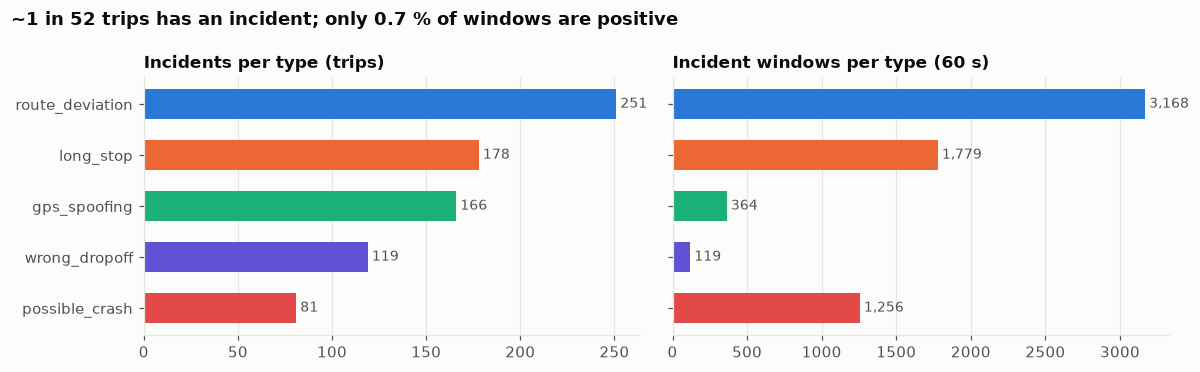

In [7]:
by_type = labels["incident_type"].value_counts().reindex(INCIDENT_TYPES)
win_by_type = windows.loc[windows["is_incident"], "incident_type"].value_counts().reindex(INCIDENT_TYPES)
duration_min = ((labels["end_ts"] - labels["start_ts"]).dt.total_seconds() / 60).groupby(labels["incident_type"]).median()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
order = by_type.sort_values().index
for ax, series, title in [(axes[0], by_type, "Incidents per type (trips)"),
                          (axes[1], win_by_type, "Incident windows per type (60 s)")]:
    s = series.reindex(order)
    ax.barh(s.index, s.values, color=[ps.color_of(t) for t in s.index], height=0.6)
    for y, v in enumerate(s.values):
        ax.text(v, y, f" {v:,}", va="center", fontsize=9, color=ps.INK_MUTED)
    ax.set_title(title); ax.grid(axis="y", visible=False)
axes[1].set_yticklabels([])
fig.suptitle("~1 in 52 trips has an incident; only 0.7 % of windows are positive", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(); ps.save(fig, "01_incidents_per_type")
pd.DataFrame({"trips": by_type, "windows": win_by_type, "median duration (min)": duration_min.reindex(INCIDENT_TYPES)})

**Does the incident rate depend on the hour?** A chi-square test of independence between night/day and incident (trip level):

In [8]:
rides["is_night"] = rides["ride_start"].dt.hour.isin([22, 23, 0, 1, 2, 3, 4, 5])
table = pd.crosstab(rides["is_night"], rides["is_incident"])
chi2, p_value, _, _ = stats.chi2_contingency(table)
rates = rides.groupby("is_night")["is_incident"].agg(["sum", "size"])
display(pd.DataFrame([ci_row("night" if night else "day", int(r["sum"]), int(r["size"])) for night, r in rates.iterrows()]).set_index("level"))
print(f"chi-square = {chi2:.2f}, p = {p_value:.3f}")

,positives,total,rate,95% CI low,95% CI high
level,,,,,
day,616,32549,0.019,0.018,0.020
night,179,9177,0.020,0.017,0.023


chi-square = 0.10, p = 0.752


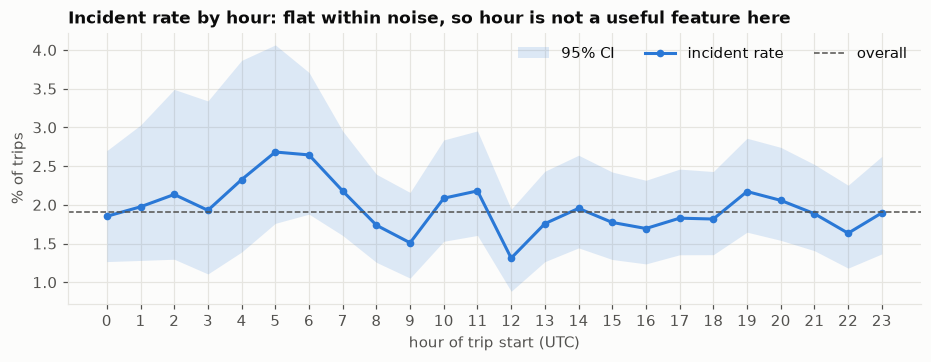

In [9]:
hourly = rides.assign(hour=rides["ride_start"].dt.hour).groupby("hour")["is_incident"].agg(["sum", "size"])
ci = np.array([rate_ci(int(k), int(n)) for k, n in hourly.to_numpy()])
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.fill_between(hourly.index, 100 * ci[:, 1], 100 * ci[:, 2], color=ps.ACCENT, alpha=0.15, linewidth=0, label="95% CI")
ax.plot(hourly.index, 100 * ci[:, 0], color=ps.ACCENT, marker="o", markersize=4, label="incident rate")
ax.axhline(100 * rides["is_incident"].mean(), color=ps.NORMAL_COLOR, linewidth=1, linestyle="--", label="overall")
ax.set_xticks(range(24)); ax.set_xlabel("hour of trip start (UTC)"); ax.set_ylabel("% of trips")
ax.set_title("Incident rate by hour: flat within noise, so hour is not a useful feature here")
ax.legend(loc="upper right", ncols=3); ps.save(fig, "02_incident_rate_by_hour")

In [10]:
pd.crosstab(rides["split"], rides["incident_type"]).reindex(["train", "valid", "test"])[INCIDENT_TYPES + ["normal"]]

incident_type,route_deviation,long_stop,wrong_dropoff,possible_crash,gps_spoofing,normal
split,,,,,,
train,160,118,83,50,110,26870
valid,51,39,22,15,29,7664
test,40,21,14,16,27,6397


## 3 · Feature separation: which signal detects which incident?

For every incident type: its incident windows vs normal windows. **AUC** = probability that a random incident window
scores higher than a random normal one (0.5 = useless). **Cliff's delta** is the matching effect size (−1 … 1).
With ~900 k windows *every* p-value is tiny, so decisions use the effect size, not the p-value.

In [11]:
clean = (windows["incident_type"] == "normal") & ~windows["after_incident"] & (windows["context"] == "none")
negatives = clean & (windows.index.isin(windows[clean].sample(200_000, random_state=42).index))

final_clean = clean & windows["is_final_window"]       # a wrong drop-off can only show on a trip's final window
tables = {t: separation_table(windows, FEATURES, t, final_clean if t == "wrong_dropoff" else negatives)
          for t in INCIDENT_TYPES}
auc = pd.DataFrame({t: tables[t]["auc"] for t in INCIDENT_TYPES}).loc[FEATURES]
auc.style.background_gradient(cmap="Blues", vmin=0.5, vmax=1).format("{:.2f}")

,route_deviation,long_stop,wrong_dropoff,possible_crash,gps_spoofing
feature,,,,,
dist_off_route_max_m,0.94,0.51,0.50,0.48,0.96
dist_off_route_mean_m,0.93,0.50,0.48,0.47,0.97
off_route_run_max_s,0.89,0.51,0.51,0.50,0.93
stop_run_max_s,0.50,0.98,0.58,0.99,0.51
stationary_share,0.50,0.98,0.60,0.99,0.51
speed_mean_kmh,0.42,0.04,0.53,0.02,0.47
speed_max_kmh,0.41,0.09,0.59,0.04,0.47
decel_max_kmh_per_s,0.47,0.12,0.61,0.07,0.50
implied_speed_max_kmh,0.41,0.08,0.60,0.04,0.88


In [12]:
top = pd.concat({t: tables[t].head(3)[["auc", "cliffs_delta", "ks", "p_value"]] for t in INCIDENT_TYPES})
top

auc  cliffs_delta     ks     p_value
                feature                                                        
route_deviation dist_off_route_max_m     0.935         0.870  0.867   0.000e+00
                dist_off_route_mean_m    0.933         0.867  0.866   0.000e+00
                off_route_run_max_s      0.891         0.782  0.782   0.000e+00
long_stop       stop_run_max_s           0.981         0.962  0.885   0.000e+00
                stationary_share         0.980         0.960  0.857   0.000e+00
                away_from_dropoff_max_m  0.870         0.740  0.749   0.000e+00
wrong_dropoff   dist_to_dropoff_last_m   1.000         1.000  1.000   2.142e-79
                decel_max_kmh_per_s      0.609         0.218  0.200   3.803e-05
                stationary_share         0.604         0.209  0.206   7.147e-56
possible_crash  stationary_share         0.989         0.978  0.932   0.000e+00
                stop_run_max_s           0.988         0.975  0.916   0.000e+00
                away_from_dropoff_max_m  0.882         0.763  0.780   0.000e+00
gps_spoofing    dist_off_route_mean_m    0.967         0.934  0.930  1.017e-208
                dist_off_route_max_m     0.964         0.928  0.931  5.520e-206
                away_from_dropoff_max_m  0.947         0.895  0.837   0.000e+00

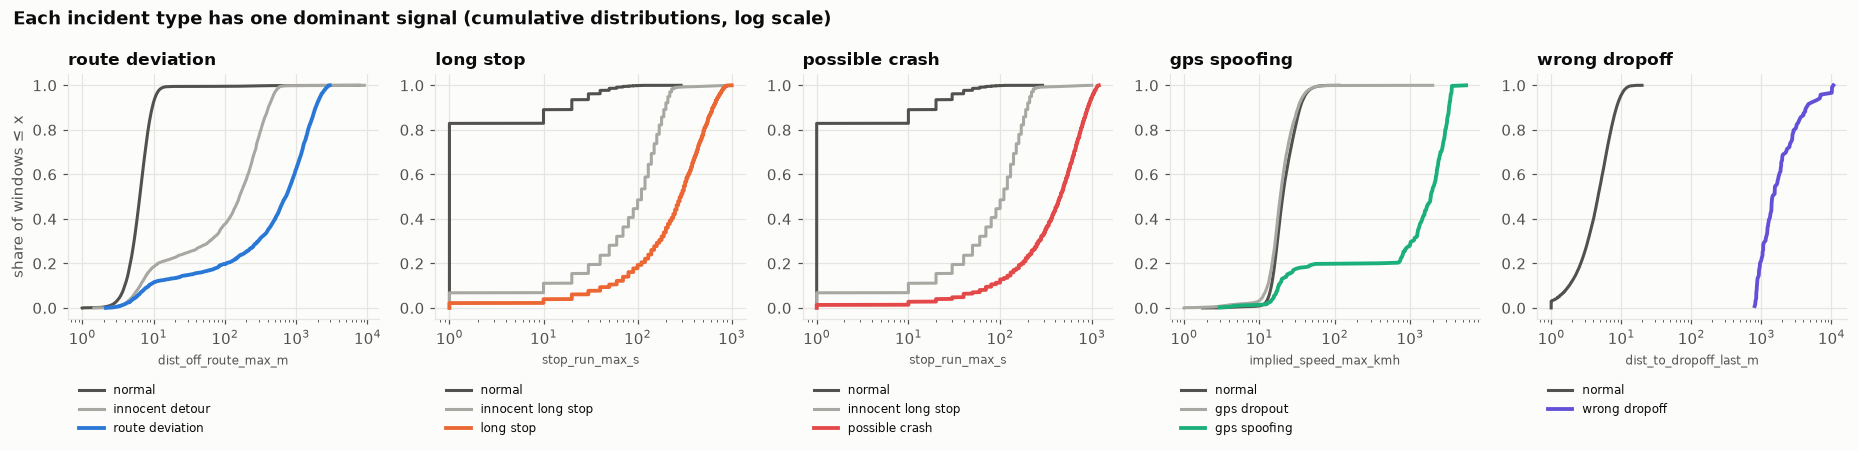

In [13]:
# The key signal of each type: distribution in incident windows vs clean normal windows vs hard negatives
KEY = {"route_deviation": ("dist_off_route_max_m", "innocent_detour"),
       "long_stop": ("stop_run_max_s", "innocent_long_stop"),
       "possible_crash": ("stop_run_max_s", "innocent_long_stop"),
       "gps_spoofing": ("implied_speed_max_kmh", "gps_dropout"),
       "wrong_dropoff": ("dist_to_dropoff_last_m", None)}

def ecdf(ax, values, color, label, lw=2):
    v = np.sort(values.dropna().to_numpy())
    ax.plot(v, np.arange(1, len(v) + 1) / len(v), color=color, label=label, linewidth=lw)

fig, axes = plt.subplots(1, 5, figsize=(17, 4.4))
for ax, (t, (feature, hard)) in zip(axes, KEY.items()):
    neg = windows.loc[negatives, feature]
    if t == "wrong_dropoff":                                   # only final windows can show a wrong drop-off
        neg = windows.loc[clean & windows["is_final_window"], feature]
    ecdf(ax, neg.clip(lower=1), ps.NORMAL_COLOR, "normal")
    if hard:
        ecdf(ax, windows.loc[windows["context"] == hard, feature].clip(lower=1), ps.HARD_NEGATIVE_COLOR, hard.replace("_", " "))
    ecdf(ax, windows.loc[windows["incident_type"] == t, feature].clip(lower=1), ps.color_of(t), t.replace("_", " "), lw=2.5)
    ax.set_xscale("log"); ax.set_title(t.replace("_", " ")); ax.set_xlabel(feature, fontsize=8)
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(0, -0.22), ncols=1)
axes[0].set_ylabel("share of windows ≤ x")
fig.suptitle("Each incident type has one dominant signal (cumulative distributions, log scale)", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(); ps.save(fig, "03_key_signal_per_type")

## 4 · Hard negatives: where false alarms will come from

The simulator adds *innocent* behaviour that looks like an incident: 2–4 min stops (pick-up help, a shop) and 200–600 m
detours (road works). A detector that cannot tell these apart will page the safety team for nothing.
Compared per trip (the worst moment of the trip):

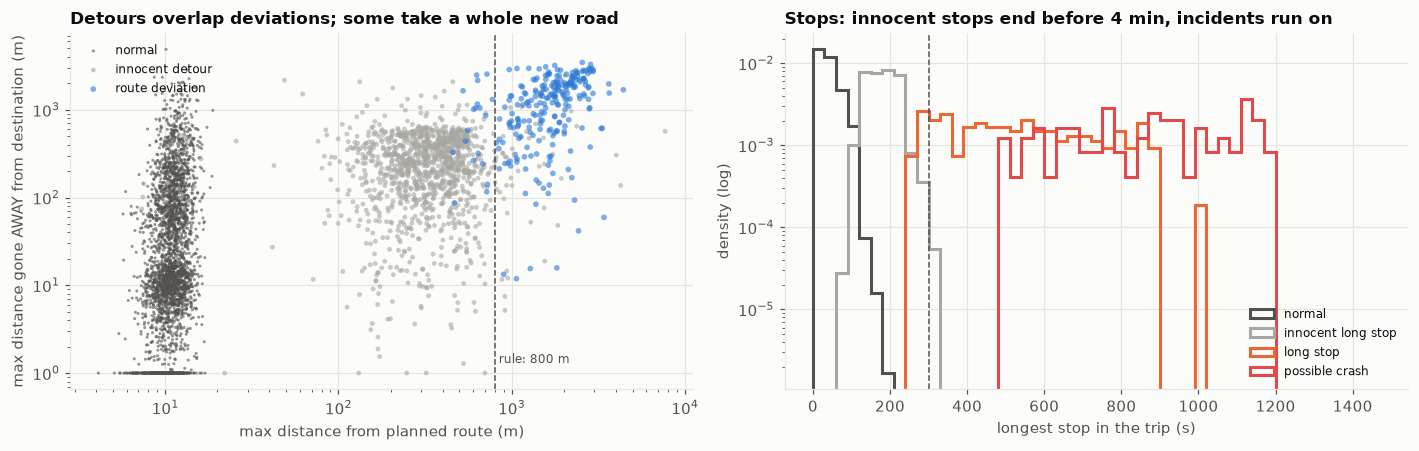

In [14]:
per_ride = windows.groupby("ride_id").agg(off_max=("dist_off_route_max_m", "max"), off_run=("off_route_run_max_s", "max"),
                                          away_max=("away_from_dropoff_max_m", "max"), stop_max=("stop_run_max_s", "max"))
per_ride = per_ride.join(rides.set_index("ride_id")[["incident_type", "has_innocent_detour", "has_innocent_long_stop"]])

def group(r, hard_col, incident):
    return np.where(r["incident_type"] == incident, incident,
           np.where((r["incident_type"] == "normal") & r[hard_col], hard_col.replace("has_", ""),
           np.where(r["incident_type"] == "normal", "normal", "other")))

per_ride["route_group"] = group(per_ride, "has_innocent_detour", "route_deviation")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
for g, size in [("normal", 4), ("innocent_detour", 10), ("route_deviation", 14)]:
    d = per_ride[per_ride["route_group"] == g]
    d = d.sample(min(len(d), 3000), random_state=1)
    ax.scatter(d["off_max"].clip(lower=1), d["away_max"].clip(lower=1), s=size, alpha=0.6, color=ps.color_of(g),
               label=g.replace("_", " "), edgecolors="none")
ax.axvline(DEFAULT_THRESHOLDS["off_route_m"], color=ps.INK_MUTED, linewidth=1, linestyle="--")
ax.text(DEFAULT_THRESHOLDS["off_route_m"], 1.3, " rule: 800 m", fontsize=8, color=ps.INK_MUTED)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("max distance from planned route (m)"); ax.set_ylabel("max distance gone AWAY from destination (m)")
ax.set_title("Detours overlap deviations; some take a whole new road"); ax.legend(loc="upper left", fontsize=8)

ax = axes[1]
per_ride["stop_group"] = np.where(per_ride["incident_type"].isin(["long_stop", "possible_crash"]), per_ride["incident_type"],
                         group(per_ride, "has_innocent_long_stop", "long_stop"))
bins = np.arange(0, 1500, 30)
for g in ["normal", "innocent_long_stop", "long_stop", "possible_crash"]:
    d = per_ride.loc[per_ride["stop_group"] == g, "stop_max"]
    ax.hist(d, bins=bins, density=True, histtype="step", linewidth=2, color=ps.color_of(g), label=g.replace("_", " "))
ax.axvline(DEFAULT_THRESHOLDS["stop_s"], color=ps.INK_MUTED, linewidth=1, linestyle="--")
ax.set_yscale("log"); ax.set_xlabel("longest stop in the trip (s)"); ax.set_ylabel("density (log)")
ax.set_title("Stops: innocent stops end before 4 min, incidents run on"); ax.legend(fontsize=8)
fig.tight_layout(); ps.save(fig, "04_hard_negatives")

In [15]:
per_ride.groupby("route_group")[["off_max", "off_run", "away_max"]].quantile([0.05, 0.5, 0.95]).unstack().round(0)

off_max                 off_run                 away_max                
                   0.05    0.50    0.95    0.05    0.50    0.95     0.05    0.50    0.95
route_group                                                                             
innocent_detour   127.0   325.0   697.0    10.0   200.0   709.0     15.0   244.0   615.0
normal              8.0    11.0    14.0     0.0     0.0     0.0      0.0    17.0   479.0
other               9.0    12.0  7920.0     0.0     0.0   100.0      6.0    80.0  7649.0
route_deviation   668.0  1665.0  2837.0   480.0  1160.0  2385.0    133.0  1313.0  2829.0

**A hard negative the simulator did not plan for.** Some innocent detours end in a *completely different road* to the
destination: one "normal" trip ran 7.7 km off its planned route for 80 minutes, while still driving to the right place.
In a real app this is everyday re-routing. So *distance from the planned route* is not enough on its own; the question is
also *is the car still closing in on the destination?*

In [16]:
alt_route = per_ride[(per_ride["route_group"] == "innocent_detour") & (per_ride["off_max"] > DEFAULT_THRESHOLDS["off_route_m"])]
print(f"innocent-detour trips beyond the 800 m rule: {len(alt_route)} "
      f"({len(alt_route) / (per_ride['route_group'] == 'innocent_detour').sum():.1%} of innocent detours)")
alt_route[["off_max", "off_run", "away_max"]].describe().round(0)

innocent-detour trips beyond the 800 m rule: 46 (3.8% of innocent detours)


,off_max,off_run,away_max
count,46.0,46.0,46.0
mean,1470.0,959.0,371.0
std,1187.0,716.0,457.0
min,801.0,290.0,5.0
25%,914.0,582.0,117.0
50%,1032.0,745.0,252.0
75%,1538.0,1135.0,477.0
max,7698.0,4980.0,2445.0


In [17]:
per_ride.groupby("stop_group")["stop_max"].quantile([0.05, 0.5, 0.95, 1.0]).unstack().round(0)

,0.05,0.50,0.95,1.00
stop_group,,,,
innocent_long_stop,120.0,180.0,230.0,320.0
long_stop,280.0,515.0,852.0,1000.0
normal,0.0,30.0,90.0,200.0
other,0.0,30.0,110.0,250.0
possible_crash,550.0,879.0,1146.0,1194.0


## 5 · Correlation and redundancy

Spearman rank correlation (robust to the heavy tails seen above) on clean normal windows.
Pairs above |ρ| = 0.8 carry the same information twice.

rho
speed_max_kmh         implied_speed_max_kmh  0.956
progress_pct_last     time_vs_plan_last      0.954
speed_max_kmh         speed_before_stop_kmh  0.907
stop_run_max_s        stationary_share       0.894
implied_speed_max_kmh speed_before_stop_kmh  0.868
speed_mean_kmh        implied_speed_max_kmh  0.841
                      speed_max_kmh          0.834

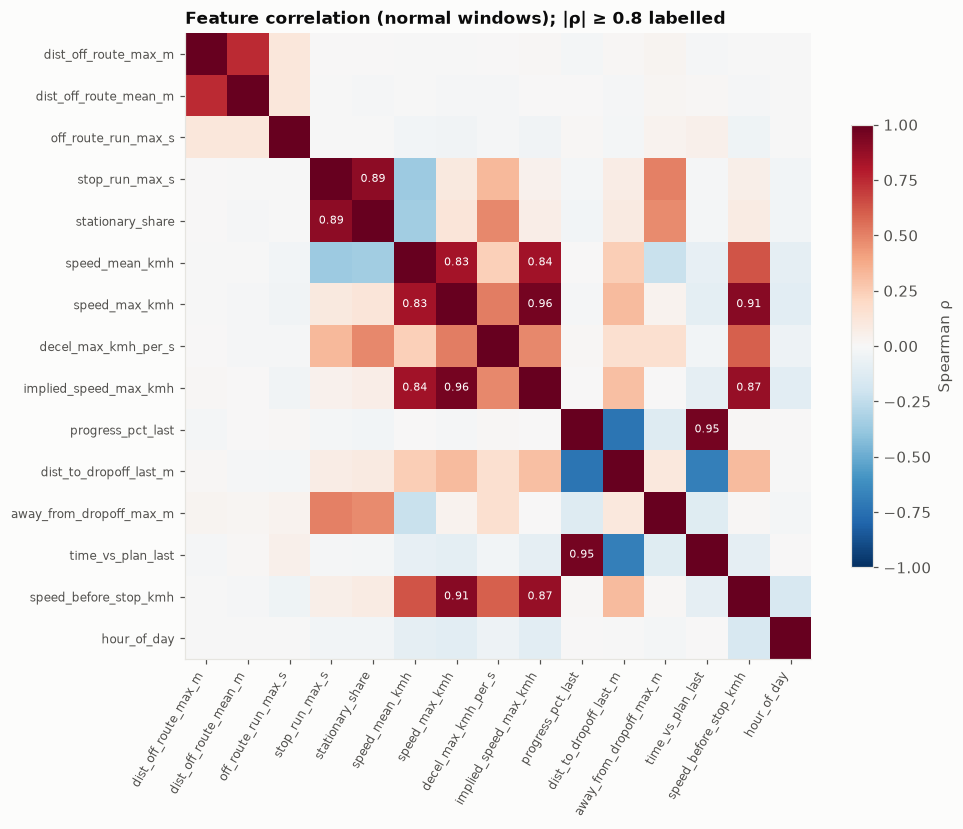

In [18]:
corr_features = [f for f in FEATURES if f not in ("n_jumps", "outside_nyc_share", "gap_max_s")]
rho = windows.loc[negatives, corr_features].sample(50_000, random_state=0).corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(rho, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(rho)), rho.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(rho)), rho.index, fontsize=8)
ax.grid(False)
for i in range(len(rho)):
    for j in range(len(rho)):
        if i != j and abs(rho.iloc[i, j]) >= 0.8:
            ax.text(j, i, f"{rho.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white")
fig.colorbar(im, ax=ax, shrink=0.7, label="Spearman ρ")
ax.set_title("Feature correlation (normal windows); |ρ| ≥ 0.8 labelled")
fig.tight_layout(); ps.save(fig, "05_feature_correlation")

pairs = rho.where(np.triu(np.ones(rho.shape, bool), 1)).stack()
pairs[pairs.abs() >= 0.8].sort_values(key=abs, ascending=False).to_frame("rho")

## 6 · Stability over time (PSI)

The split is by time: train on days 1–5, validate on day 6, test on day 7, as in production (never train on the future).
That is only fair if feature distributions do not shift between days. PSI < 0.1 = stable.

In [19]:
train_neg = windows.loc[clean & (windows["split"] == "train")]
psi_table = pd.DataFrame({
    s: {f: psi(train_neg[f], windows.loc[clean & (windows["split"] == s), f]) for f in FEATURES}
    for s in ["valid", "test"]
})
psi_table["status"] = np.where(psi_table.max(axis=1) < 0.1, "stable", np.where(psi_table.max(axis=1) < 0.25, "watch", "shifted"))
psi_table.sort_values("test", ascending=False)

,valid,test,status
hour_of_day,1.043e-01,1.240e-01,watch
speed_max_kmh,7.616e-02,8.282e-02,stable
speed_before_stop_kmh,5.612e-02,7.453e-02,stable
implied_speed_max_kmh,6.353e-02,7.192e-02,stable
speed_mean_kmh,4.885e-02,5.478e-02,stable
decel_max_kmh_per_s,1.503e-02,1.816e-02,stable
stationary_share,1.643e-03,1.741e-03,stable
stop_run_max_s,7.186e-04,8.560e-04,stable
dist_to_dropoff_last_m,3.713e-04,3.482e-04,stable
away_from_dropoff_max_m,4.682e-04,3.136e-04,stable


## 7 · Feature engineering

Three changes went into the **shared** module (`safety_features.py`), so Silver and training compute them identically:

| Change | Type | Why |
|---|---|---|
| `MIN_DT_S = 2` | data-quality fix | no speed from pings < 2 s apart (section 1): 10 false "jumps" per 1k trips → 0 |
| `off_route_run_s` → `off_route_run_max_s` | new feature | seconds continuously > 100 m off route: *persistence*, not one far point |
| `away_from_dropoff_m` → `away_from_dropoff_max_m` | new feature | distance gone back from the closest point to the destination so far: re-routing closes in, deviation drives away |

Both new features use only past pings, so they work on the live stream.

**Does each feature add information?** Tested on the hardest windows only: off-route windows (> 100 m) of route deviations vs
innocent-detour trips. A small logistic regression, 5-fold cross-validation **grouped by ride** (windows of one ride never
sit in both train and test folds, which would inflate the score).

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

detour_rides = set(windows.loc[windows["context"] == "innocent_detour", "ride_id"])
hard_set = windows[(windows["incident_type"] == "route_deviation")
                   | (windows["ride_id"].isin(detour_rides) & (windows["incident_type"] == "normal")
                      & ~windows["after_incident"] & (windows["dist_off_route_max_m"] > 100))]
y = (hard_set["incident_type"] == "route_deviation").astype(int)

def cv_auc(cols):
    X = np.log1p(hard_set[cols].fillna(0).clip(lower=0))      # heavy tails -> log scale
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    return cross_val_score(model, X, y, cv=GroupKFold(5), groups=hard_set["ride_id"], scoring="roc_auc").mean()

uni = {f: separation(hard_set.loc[y == 1, f], hard_set.loc[y == 0, f])["auc"]
       for f in ["dist_off_route_max_m", "off_route_run_max_s", "away_from_dropoff_max_m"]}
combos = {
    "distance from route": ["dist_off_route_max_m"],
    "+ time off route": ["dist_off_route_max_m", "off_route_run_max_s"],
    "+ away from destination": ["dist_off_route_max_m", "away_from_dropoff_max_m"],
    "all three": ["dist_off_route_max_m", "off_route_run_max_s", "away_from_dropoff_max_m"],
}
print(f"hard set: {len(hard_set):,} windows, {y.mean():.0%} deviation")
display(pd.Series(uni, name="univariate AUC").to_frame())
pd.Series({k: cv_auc(v) for k, v in combos.items()}, name="grouped 5-fold CV AUC").to_frame()

hard set: 10,023 windows, 32% deviation


,univariate AUC
dist_off_route_max_m,0.673
off_route_run_max_s,0.510
away_from_dropoff_max_m,0.729


,grouped 5-fold CV AUC
distance from route,0.673
+ time off route,0.741
+ away from destination,0.736
all three,0.765


Alone, each new feature looks no better than distance (univariate AUC). **Together** they lift the hard-set AUC clearly,
because they describe different things: how far, how long, and in which direction. A threshold rule cannot combine them;
a model can. This is the main argument for M11.

Candidates tried and **not** added:

| Candidate | Why rejected |
|---|---|
| Change in distance to drop-off over 60 s | Too noisy at 60 s; the "so far" version above captures it |
| Hour of day / night flag | Incident rate flat across hours (section 2) |
| Deceleration before a stop (crash signature) | Crash windows show no sharper braking than long stops in this data |

## 8 · Rule-based baseline

What a safety team would ship before any ML: one readable rule per signal (`ml/rules.py`). Thresholds are tuned on the
**train days only**, then measured once on validation and test. Metrics are event-level (`ml/metrics.py`): recall per incident,
false alarms per 1,000 trips, and detection delay.

Threshold sweep on train for the two rules with a real trade-off:

In [21]:
train_w = windows[windows["split"] == "train"]
train_labels = labels[labels["ride_id"].isin(train_w["ride_id"])]

def sweep(param, values):
    rows = []
    for v in values:
        r = evaluate(apply_rules(train_w, {param: v}), train_labels)
        rows.append({param: v, "recall": r["recall"], "false_alarms_per_1k": r["false_alarms_per_1k_trips"],
                     "median_delay_s": r["median_delay_s"]})
    return pd.DataFrame(rows).set_index(param)

stop_sweep = sweep("stop_s", [150, 180, 210, 240, 270, 300, 360, 420])
off_sweep = sweep("off_route_m", [300, 400, 500, 600, 700, 800, 1000, 1200])
display(stop_sweep); display(off_sweep)

,recall,false_alarms_per_1k,median_delay_s
stop_s,,,
150,0.973,20.700,191.400
180,0.973,13.545,212.950
210,0.973,5.878,243.367
240,0.971,1.716,267.412
270,0.969,1.168,297.839
300,0.948,1.059,320.894
360,0.916,1.022,326.925
420,0.896,1.022,316.383


,recall,false_alarms_per_1k,median_delay_s
off_route_m,,,
300,0.975,16.867,198.779
400,0.975,11.245,224.925
500,0.975,5.330,269.615
600,0.965,2.337,303.787
700,0.950,1.387,317.478
800,0.948,1.059,320.894
1000,0.919,0.548,324.970
1200,0.885,0.402,325.562


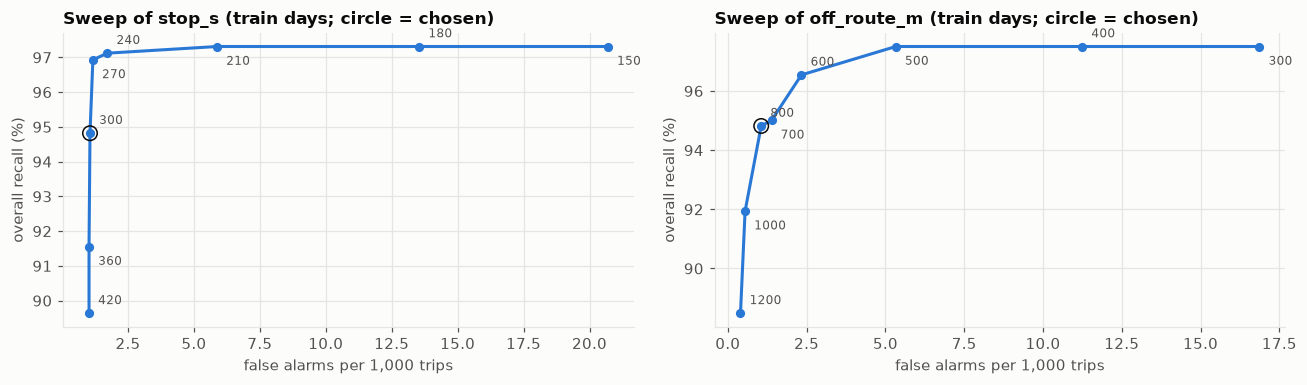

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, sw, name in [(axes[0], stop_sweep, "stop_s"), (axes[1], off_sweep, "off_route_m")]:
    ax.plot(sw["false_alarms_per_1k"], 100 * sw["recall"], color=ps.ACCENT, marker="o", markersize=5)
    for k, (v, r) in enumerate(sw.iterrows()):
        ax.annotate(f"{v:g}", (r["false_alarms_per_1k"], 100 * r["recall"]), textcoords="offset points", xytext=(6, 6 if k % 2 else -12),
                    fontsize=8, color=ps.INK_MUTED)
    chosen = sw.loc[DEFAULT_THRESHOLDS[name]]
    ax.scatter([chosen["false_alarms_per_1k"]], [100 * chosen["recall"]], s=90, facecolors="none", edgecolors=ps.INK, zorder=3)
    ax.set_xlabel("false alarms per 1,000 trips"); ax.set_ylabel("overall recall (%)")
    ax.set_title(f"Sweep of {name} (train days; circle = chosen)")
fig.tight_layout(); ps.save(fig, "06_rule_threshold_tradeoff")

In [23]:
results = {s: evaluate(apply_rules(windows[windows["split"] == s]), labels) for s in ["train", "valid", "test"]}
pd.DataFrame([summary_row(f"rules · {s}", r) for s, r in results.items()]).set_index("detector").T

detector,rules · train,rules · valid,rules · test
recall,0.948,0.904,0.966
precision,0.937,0.928,0.919
false_alarms_per_1k_trips,1.059,1.151,1.688
median_delay_s,320.894,321.660,304.602
recall_route_deviation,0.912,0.843,0.925
recall_long_stop,0.890,0.821,0.952
recall_wrong_dropoff,1.000,1.000,1.000
recall_possible_crash,1.000,1.000,1.000
recall_gps_spoofing,1.000,1.000,1.000


In [24]:
test = results["test"]["by_type"]
test

,incidents,detected,median_delay_s,p90_delay_s,recall
incident_type,,,,,
route_deviation,40,37,322.213,450.230,0.925
long_stop,21,20,339.228,370.274,0.952
wrong_dropoff,14,14,22.069,51.718,1.000
possible_crash,16,16,345.602,361.721,1.000
gps_spoofing,27,27,33.765,56.326,1.000


In [25]:
# Error analysis on the test day: what triggers the false alarms?
test_w = apply_rules(windows[windows["split"] == "test"])
fa = test_w[test_w["alert"] & ~test_w["is_incident"] & ~test_w["after_incident"]]
fa_rides = fa.groupby("ride_id")["alert_type"].first().to_frame("rule").join(rides.set_index("ride_id"))
fa_rides["cause"] = np.select(
    [fa_rides["has_innocent_detour"], fa_rides["has_innocent_long_stop"], fa_rides["has_gps_dropout"], fa_rides["is_incident"]],
    ["innocent detour / re-route", "innocent long stop", "GPS dropout", "incident trip, before incident"], "none found")
pd.crosstab(fa_rides["rule"], fa_rides["cause"], margins=True)

cause,innocent detour / re-route,All
rule,,
route_deviation,11,11
All,11,11


In [26]:
# Missed incidents on the test day
det = detections(test_w, labels)
det[~det["detected"]].merge(labels[["incident_id", "params", "severity"]], on="incident_id")[["incident_type", "severity", "params"]]

,incident_type,severity,params
0,route_deviation,medium,"{""detour_m"": 2498}"
1,long_stop,low,"{""stop_s"": 279}"
2,route_deviation,low,"{""detour_m"": 1293}"
3,route_deviation,medium,"{""detour_m"": 1725}"


## 9 · Findings

| # | Finding | Evidence | Decision |
|---|---|---|---|
| 1 | Pings are clean: 99.2 % exactly 10 s apart, 0.1 % gaps, accuracy p99 8 m; normal trips stay within 12 m of the route (p99) | §1 | Features can be trusted |
| 2 | **Bug:** pings < 0.3 s apart made 10 false "jumps" per 1k normal trips | §1 | Fixed in the shared module (`MIN_DT_S = 2`): now 0 |
| 3 | Extreme imbalance: 1.9 % of trips (95 % CI 1.8–2.0 %), 0.7 % of windows | §2 | Event-level metrics, never accuracy; class weights + threshold tuning in M11 |
| 4 | Incident rate does not depend on the hour (χ² p = 0.75); hour's own distribution shifts by day (PSI 0.12) | §2, §6 | `hour_of_day` / `is_night` left out of the model |
| 5 | Each type has one dominant signal: stop length (AUC 0.98–0.99), distance from route (0.94), impossible speed / far-off position (0.96), end distance to drop-off (1.00 on final windows) | §3 | Strong baseline is possible with simple rules |
| 6 | Hard negatives decide the false alarms: innocent stops reach 320 s vs long stops from 280 s; 3.8 % of innocent detours turn into a whole new road (up to 7.7 km off route) | §4 | Every false alarm of the baseline on the test day was a detour / re-route |
| 7 | 7 feature pairs with \|ρ\| ≥ 0.8 (e.g. max speed vs implied speed 0.96, progress vs time-vs-plan 0.95) | §5 | Fine for trees; drop one per pair for linear models and for clean SHAP readings |
| 8 | All model features stable across days (PSI < 0.1) | §6 | Time-based split (days 1–5 / 6 / 7) is safe |
| 9 | New features `off_route_run_max_s` + `away_from_dropoff_max_m`: hard-set AUC 0.67 → 0.77 together, despite weak univariate AUC | §7 | Added to the shared module (Silver gets them too) |
| 10 | **Rule baseline, test day:** recall 96.6 %, precision 91.9 %, 1.7 false alarms / 1k trips, median detection delay 5 min | §8 | The bar for M11 |

**What M11 must beat.** Spoofing and wrong drop-offs are already caught in under a minute. The room for ML is
(a) **detection delay** for stops, crashes and deviations (about 5–6 minutes with rules, because a threshold must wait
until the stop or the distance is unambiguous) and (b) **detour / re-route false alarms**, which only a combination of
distance, duration and direction can separate. Test-day incident counts are small (118), so M11 results will be
reported with confidence intervals and thresholds will be chosen on the validation day only.